# Project: Investigating the TMDb Movie Dataset

## Table of Contents
<ul>
<li><a href="#intro">Introduction</a></li>
<li><a href="#wrangling">Data Wrangling</a></li>
<li><a href="#eda">Exploratory Data Analysis</a></li>
<li><a href="#conclusions">Conclusions</a></li>
</ul>

<a id='intro'></a>
## Introduction

### Dataset Description

This project investigates the TMDb Movie Dataset, which contains 10,866 records and 21 columns covering movies released between 1960 and 2015. The purpose is to explore movie characteristics and their associations with movie revenue using pandas, NumPy, and visualizations.

The dataset contains the following columns:

| Column | Description |
| --- | --- |
| `id` | TMDb movie identifier. |
| `imdb_id` | IMDb movie identifier. |
| `popularity` | Movie popularity score recorded by TMDb. |
| `budget` | Reported movie budget in US dollars, without inflation adjustment. |
| `revenue` | Reported movie revenue in US dollars, without inflation adjustment. |
| `original_title` | Original movie title. |
| `cast` | Cast members, separated by `\|`. |
| `homepage` | Movie homepage URL. |
| `director` | Movie director or directors. |
| `tagline` | Movie promotional tagline. |
| `keywords` | Keywords describing the movie. |
| `overview` | Brief movie synopsis. |
| `runtime` | Movie runtime in minutes. |
| `genres` | Movie genres, separated by `\|`; a movie may have multiple genres. |
| `production_companies` | Production companies associated with the movie. |
| `release_date` | Movie release date. |
| `vote_count` | Number of recorded audience votes. |
| `vote_average` | Average audience rating. |
| `release_year` | Movie release year. |
| `budget_adj` | Movie budget adjusted for inflation to 2010 US dollars. |
| `revenue_adj` | Movie revenue adjusted for inflation to 2010 US dollars. |

Adjusted revenue is the main outcome variable. Adjusted budget, audience rating, runtime, genre, and release period are examined in relation to it. All subsequent exploratory analyses use the same subset of 3,854 movies with positive adjusted budgets and revenues; the implications of this restriction are discussed below.

### Research Questions

1. How are adjusted movie budgets, audience ratings, and runtime associated with adjusted movie revenue?
2. How does adjusted movie revenue vary across genres and five-year release periods?

In [48]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

<a id='wrangling'></a>
## Data Wrangling

### General Properties

This section examines the dataset's dimensions, data types, summary statistics, missing values, and duplicate records to identify data quality issues before cleaning.

In [49]:
# Load the TMDb movie dataset
df = pd.read_csv(r'Database_TMDb_movie_data\tmdb-movies.csv')

# Display the first five rows
df.head()

,id,imdb_id,popularity,budget,revenue,original_title,cast,homepage,director,tagline,...,overview,runtime,genres,production_companies,release_date,vote_count,vote_average,release_year,budget_adj,revenue_adj
0,135397,tt0369610,32.985763,150000000,1513528810,Jurassic World,Chris Pratt|Bryce Dallas Howard|Irrfan Khan|Vi...,http://www.jurassicworld.com/,Colin Trevorrow,The park is open.,...,Twenty-two years after the events of Jurassic ...,124,Action|Adventure|Science Fiction|Thriller,Universal Studios|Amblin Entertainment|Legenda...,6/9/15,5562,6.5,2015,1.379999e+08,1.392446e+09
1,76341,tt1392190,28.419936,150000000,378436354,Mad Max: Fury Road,Tom Hardy|Charlize Theron|Hugh Keays-Byrne|Nic...,http://www.madmaxmovie.com/,George Miller,What a Lovely Day.,...,An apocalyptic story set in the furthest reach...,120,Action|Adventure|Science Fiction|Thriller,Village Roadshow Pictures|Kennedy Miller Produ...,5/13/15,6185,7.1,2015,1.379999e+08,3.481613e+08
2,262500,tt2908446,13.112507,110000000,295238201,Insurgent,Shailene Woodley|Theo James|Kate Winslet|Ansel...,http://www.thedivergentseries.movie/#insurgent,Robert Schwentke,One Choice Can Destroy You,...,Beatrice Prior must confront her inner demons ...,119,Adventure|Science Fiction|Thriller,Summit Entertainment|Mandeville Films|Red Wago...,3/18/15,2480,6.3,2015,1.012000e+08,2.716190e+08
3,140607,tt2488496,11.173104,200000000,2068178225,Star Wars: The Force Awakens,Harrison Ford|Mark Hamill|Carrie Fisher|Adam D...,http://www.starwars.com/films/star-wars-episod...,J.J. Abrams,Every generation has a story.,...,Thirty years after defeating the Galactic Empi...,136,Action|Adventure|Science Fiction|Fantasy,Lucasfilm|Truenorth Productions|Bad Robot,12/15/15,5292,7.5,2015,1.839999e+08,1.902723e+09
4,168259,tt2820852,9.335014,190000000,1506249360,Furious 7,Vin Diesel|Paul Walker|Jason Statham|Michelle ...,http://www.furious7.com/,James Wan,Vengeance Hits Home,...,Deckard Shaw seeks revenge against Dominic Tor...,137,Action|Crime|Thriller,Universal Pictures|Original Film|Media Rights ...,4/1/15,2947,7.3,2015,1.747999e+08,1.385749e+09


The dataset was loaded successfully using pandas. The first five rows show movie-related information, including titles, budgets, revenues, ratings, genres, runtime, and release years. The dataset contains 21 columns. Further inspection is needed to determine the total number of records, data types, missing values, and duplicates.

In [50]:
# Check the number of rows and columns
df.shape

(10866, 21)

The TMDb movie dataset contains 10,866 records and 21 columns.

In [51]:
# Inspect column data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10866 entries, 0 to 10865
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    10866 non-null  int64  
 1   imdb_id               10856 non-null  str    
 2   popularity            10866 non-null  float64
 3   budget                10866 non-null  int64  
 4   revenue               10866 non-null  int64  
 5   original_title        10866 non-null  str    
 6   cast                  10790 non-null  str    
 7   homepage              2936 non-null   str    
 8   director              10822 non-null  str    
 9   tagline               8042 non-null   str    
 10  keywords              9373 non-null   str    
 11  overview              10862 non-null  str    
 12  runtime               10866 non-null  int64  
 13  genres                10843 non-null  str    
 14  production_companies  9836 non-null   str    
 15  release_date          10866 no

The dataset contains 10,866 rows and 21 columns. It includes 6 integer columns, 4 floating-point columns, and 11 string columns.

Initial inspection shows missing values in several columns, including `homepage`, `tagline`, `keywords`, `production_companies`, `cast`, `director`, and `genres`.

The main numerical variables selected for this investigation, including adjusted budget, adjusted revenue, vote average, runtime, and release year, have no missing values according to `df.info()`. However, further inspection is necessary to identify potentially invalid or zero values before making any cleaning decisions.

In [52]:
# Generate summary statistics
df.describe().style.format('{:,.2f}')

,id,popularity,budget,revenue,runtime,vote_count,vote_average,release_year,budget_adj,revenue_adj
count,"10,866.00","10,866.00","10,866.00","10,866.00","10,866.00","10,866.00","10,866.00","10,866.00","10,866.00","10,866.00"
mean,"66,064.18",0.65,"14,625,701.09","39,823,319.79",102.07,217.39,5.97,"2,001.32","17,551,039.82","51,364,363.25"
std,"92,130.14",1.00,"30,913,213.83","117,003,486.58",31.38,575.62,0.94,12.81,"34,306,155.72","144,632,485.04"
min,5.00,0.00,0.00,0.00,0.00,10.00,1.50,"1,960.00",0.00,0.00
25%,"10,596.25",0.21,0.00,0.00,90.00,17.00,5.40,"1,995.00",0.00,0.00
50%,"20,669.00",0.38,0.00,0.00,99.00,38.00,6.00,"2,006.00",0.00,0.00
75%,"75,610.00",0.71,"15,000,000.00","24,000,000.00",111.00,145.75,6.60,"2,011.00","20,853,251.08","33,697,095.72"
max,"417,859.00",32.99,"425,000,000.00","2,781,505,847.00",900.00,"9,767.00",9.20,"2,015.00","425,000,000.00","2,827,123,750.41"


### Summary Statistics Findings

The descriptive statistics reveal several important characteristics of the dataset:

- The median values of both `budget_adj` and `revenue_adj` are zero, indicating that at least half of the records have zero values in each of these columns. These values require further investigation before conducting revenue-related analysis.
- The `runtime` column ranges from 0 to 900 minutes, with a median of 99 minutes. The zero and unusually high runtime values should be examined.
- Movie ratings (`vote_average`) range from 1.5 to 9.2, with a median of 6.0.
- The dataset includes movies released between 1960 and 2015.

These observations highlight potential data quality issues that will be investigated further before making cleaning decisions.

In [53]:
# Count missing values in each column
df.isnull().sum()

id                         0
imdb_id                   10
popularity                 0
budget                     0
revenue                    0
original_title             0
cast                      76
homepage                7930
director                  44
tagline                 2824
keywords                1493
overview                   4
runtime                    0
genres                    23
production_companies    1030
release_date               0
vote_count                 0
vote_average               0
release_year               0
budget_adj                 0
revenue_adj                0
dtype: int64

### Missing Values Assessment

The missing value analysis shows that several columns contain incomplete data. The `homepage` column has the highest number of missing values (7,930), followed by `tagline` (2,824), `keywords` (1,493), and `production_companies` (1,030).

Most variables relevant to the main research questions have no missing values. However, the `genres` column contains 23 missing values.

Missing values will be handled during the data cleaning stage based on their relevance to the analysis. Zero values in numerical columns will also require separate investigation, since they are not identified as missing by `isnull()`.

In [54]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(1)

### Duplicate Records Assessment

The initial duplicate check identified one fully duplicated row in the dataset. The duplicated records will be inspected before removing the redundant entry during the data cleaning stage.

In [55]:
# Display duplicated records
df[df.duplicated(keep=False)]

,id,imdb_id,popularity,budget,revenue,original_title,cast,homepage,director,tagline,...,overview,runtime,genres,production_companies,release_date,vote_count,vote_average,release_year,budget_adj,revenue_adj
2089,42194,tt0411951,0.59643,30000000,967000,TEKKEN,Jon Foo|Kelly Overton|Cary-Hiroyuki Tagawa|Ian...,NaN,Dwight H. Little,Survival is no game,...,"In the year of 2039, after World Wars destroy ...",92,Crime|Drama|Action|Thriller|Science Fiction,Namco|Light Song Films,3/20/10,110,5.0,2010,30000000.0,967000.0
2090,42194,tt0411951,0.59643,30000000,967000,TEKKEN,Jon Foo|Kelly Overton|Cary-Hiroyuki Tagawa|Ian...,NaN,Dwight H. Little,Survival is no game,...,"In the year of 2039, after World Wars destroy ...",92,Crime|Drama|Action|Thriller|Science Fiction,Namco|Light Song Films,3/20/10,110,5.0,2010,30000000.0,967000.0


### Data Cleaning

The following steps remove the duplicated record, examine zero financial and runtime values, and prepare the financial subset used throughout the exploratory analysis. The original DataFrame is preserved.

In [56]:
# Create a copy of the dataset and remove duplicate rows
df_clean = df.drop_duplicates().copy()

# Check the shape after removing duplicates
df_clean.shape

(10865, 21)

In [57]:
# Verify that no duplicate rows remain
df_clean.duplicated().sum()

np.int64(0)

### Removing Duplicate Records

One fully duplicated record was identified in the dataset. I removed the duplicate to avoid counting the same movie twice in the analysis, while preserving the original dataset in a separate DataFrame.

In [58]:
# Count zero values in important numerical columns
columns_to_check = ['budget_adj', 'revenue_adj', 'runtime']

(df_clean[columns_to_check] == 0).sum()

budget_adj     5696
revenue_adj    6016
runtime          31
dtype: int64

In [59]:
# Count movies with positive budget and revenue
both_positive = (
    (df_clean['budget_adj'] > 0) &
    (df_clean['revenue_adj'] > 0)
).sum()

# Count movies with zero budget and revenue
both_zero = (
    (df_clean['budget_adj'] == 0) &
    (df_clean['revenue_adj'] == 0)
).sum()

print("Movies with positive budget and revenue:", both_positive)
print("Movies with zero budget and revenue:", both_zero)

Movies with positive budget and revenue: 3854
Movies with zero budget and revenue: 4701


### Investigating Zero Values

The dataset contains 5,696 zero values in `budget_adj`, 6,016 in `revenue_adj`, and 31 in `runtime`. These values require further investigation because they may affect the accuracy and representativeness of the analysis. No records have been removed based on zero values at this stage.

In [60]:
# Create a subset for budget and revenue analysis
df_financial = df_clean[
    (df_clean['budget_adj'] > 0) &
    (df_clean['revenue_adj'] > 0)
].copy()

# Check the shape of the financial subset
df_financial.shape

(3854, 21)

### Preparing Financial Data

Only 3,854 movies have both positive adjusted budgets and revenues. These movies were selected into a separate DataFrame, `df_financial`, for the budget-revenue analysis. Zero financial values were excluded because their meaning is uncertain; they were not assumed to represent confirmed zero expenditure or earnings.

The same financial subset is used for the rating, runtime, genre, and release-period analyses to keep comparisons focused on a consistent set of movies. The full cleaned dataset remains available in `df_clean`.

This restriction may introduce selection bias. In particular, it excludes movies with positive reported revenue but a zero reported budget, even though they could otherwise contribute to revenue comparisons by genre or release period. The findings therefore describe this financial subset rather than all movies in the dataset.

In [61]:
# Count zero runtime values in the financial subset
(df_financial['runtime'] == 0).sum()

np.int64(0)

### Runtime Validation

The financial subset contains no movies with a runtime of zero minutes. Therefore, no additional records need to be removed due to zero runtime values before analyzing the relationship between runtime and revenue.

In [62]:
# Check missing genres in the financial subset
df_financial['genres'].isnull().sum()

np.int64(0)

### Checking Missing Values in Genres

The `genres` column contains no missing values in `df_financial`, so no additional missing-value cleaning is required for genre analysis in this subset.

The column contains multiple genres separated by `|`. These entries are split during the exploratory analysis so that each movie contributes to every genre associated with it.

In [63]:
# Inspect the main variables in the final analysis dataset
df_financial[
    ['budget_adj', 'revenue_adj', 'vote_average',
     'runtime', 'release_year']
].describe().style.format('{:,.2f}')

,budget_adj,revenue_adj,vote_average,runtime,release_year
count,"3,854.00","3,854.00","3,854.00","3,854.00","3,854.00"
mean,"44,239,993.08","137,064,690.30",6.17,109.22,"2,001.26"
std,"44,809,254.03","216,111,351.44",0.79,19.92,11.28
min,0.97,2.37,2.20,15.00,"1,960.00"
25%,"13,090,528.47","18,357,350.36",5.70,95.00,"1,995.00"
50%,"30,016,111.91","61,730,679.08",6.20,106.00,"2,004.00"
75%,"60,613,069.68","163,257,654.56",6.70,119.00,"2,010.00"
max,"425,000,000.00","2,827,123,750.41",8.40,338.00,"2,015.00"


### Financial Dataset Summary

The financial dataset contains 3,854 movies with positive adjusted budgets and revenues.

The average adjusted revenue is approximately $137.06 million, while the median is approximately $61.73 million, suggesting a right-skewed distribution.

The dataset contains some very small positive budget and revenue values. These values were retained because there is insufficient evidence to classify them as errors.

<a id='eda'></a>
## Exploratory Data Analysis

The following analyses examine distributions and relationships within the financial subset of 3,854 movies. All financial comparisons use values adjusted to 2010 US dollars.

### Research Question 1: How Are Budget, Audience Ratings, and Runtime Associated with Adjusted Revenue?

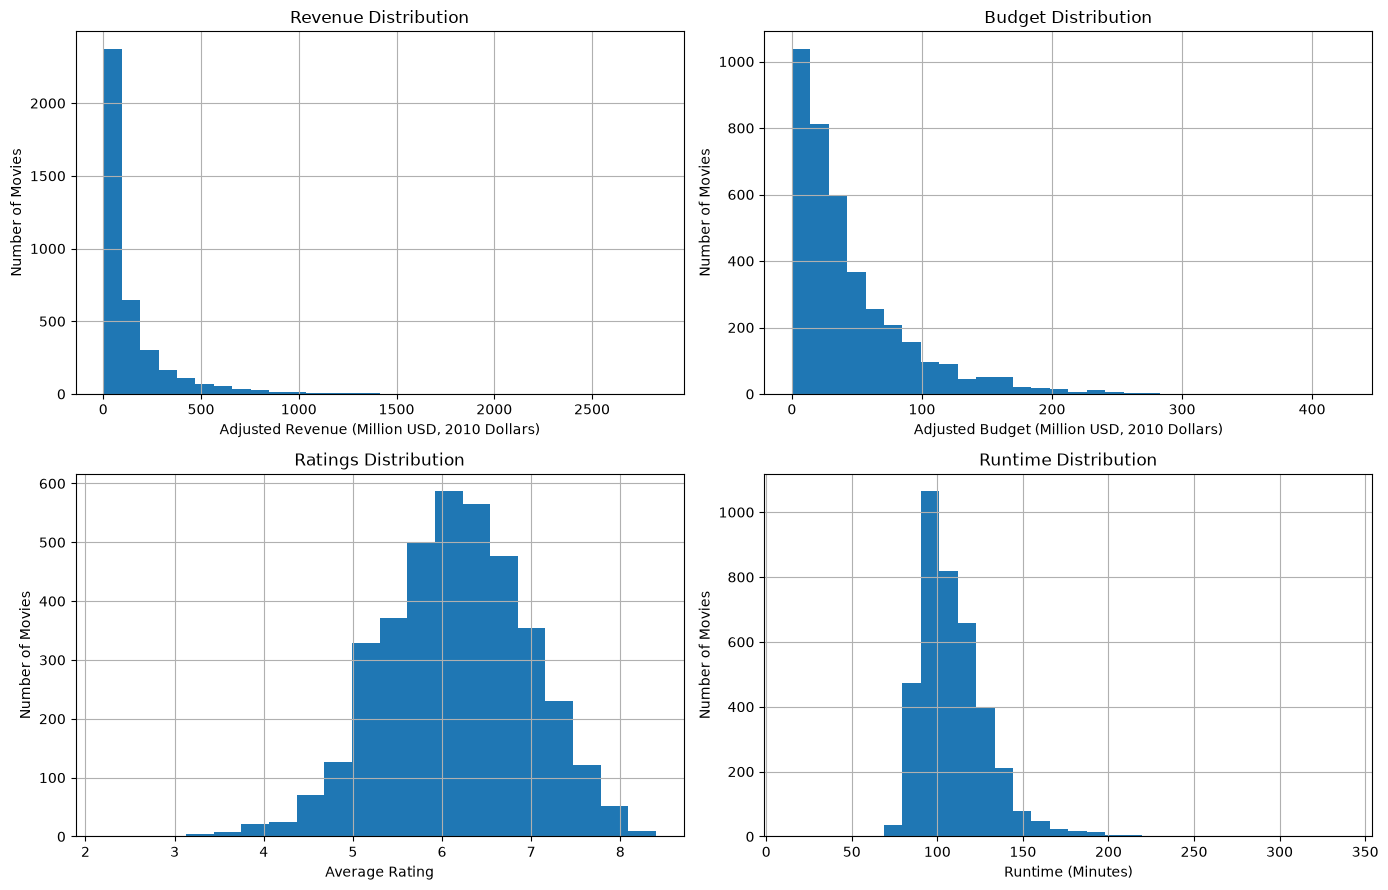

In [64]:
# Reusable function for plotting distributions
def plot_distribution(column, title, xlabel, ax, bins=30, scale=1):
    data = df_financial[column] / scale

    data.hist(bins=bins, ax=ax)

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Number of Movies')


# Create a 2x2 layout
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Revenue
plot_distribution(
    'revenue_adj',
    'Revenue Distribution',
    'Adjusted Revenue (Million USD, 2010 Dollars)',
    axes[0, 0],
    scale=1_000_000
)

# Budget
plot_distribution(
    'budget_adj',
    'Budget Distribution',
    'Adjusted Budget (Million USD, 2010 Dollars)',
    axes[0, 1],
    scale=1_000_000
)

# Ratings
plot_distribution(
    'vote_average',
    'Ratings Distribution',
    'Average Rating',
    axes[1, 0],
    bins=20
)

# Runtime
plot_distribution(
    'runtime',
    'Runtime Distribution',
    'Runtime (Minutes)',
    axes[1, 1]
)

plt.tight_layout();

### Univariate Analysis (1D): Distribution of Key Movie Variables

The four histograms illustrate the distributions of adjusted revenue, adjusted budget, movie ratings, and runtime for the 3,854 movies in the financial dataset.

**1. Adjusted Revenue**

The distribution is strongly right-skewed. Most movies generate relatively low revenues, while a small number achieve exceptionally high revenues. The mean revenue is approximately $137.06 million, compared with a median of $61.73 million.

**2. Adjusted Budget**

Movie budgets are also right-skewed. Most movies have relatively lower budgets, while a smaller number have substantially higher budgets. The mean budget is approximately $44.24 million, compared with a median of $30.02 million.

**3. Movie Ratings**

Most movie ratings are concentrated between 5 and 7, with the highest frequency around 6 to 6.5. The mean rating is 6.17, while the median is 6.20, suggesting a relatively balanced center.

**4. Movie Runtime**

Most movies have runtimes between approximately 90 and 120 minutes. The mean runtime is 109.22 minutes, while the median is 106 minutes. The distribution is slightly right-skewed, with a small number of much longer movies.

**Overall Observation**

Revenue and budget show more pronounced right-skewed distributions than ratings and runtime. These distributions provide useful context for investigating how budget, ratings, and runtime are associated with movie revenue.

For the scatter plots below, NumPy applies a base-10 logarithm to the adjusted budget and revenue arrays. This compresses the large range of financial values and makes patterns among lower-value movies easier to see. For example, $1 million becomes 6 and $10 million becomes 7; a one-unit increase represents a tenfold increase in the original amount. Both financial columns are strictly positive in this subset, so the logarithms are defined. The original columns are retained for summary statistics, Spearman correlations, and genre and release-period comparisons.

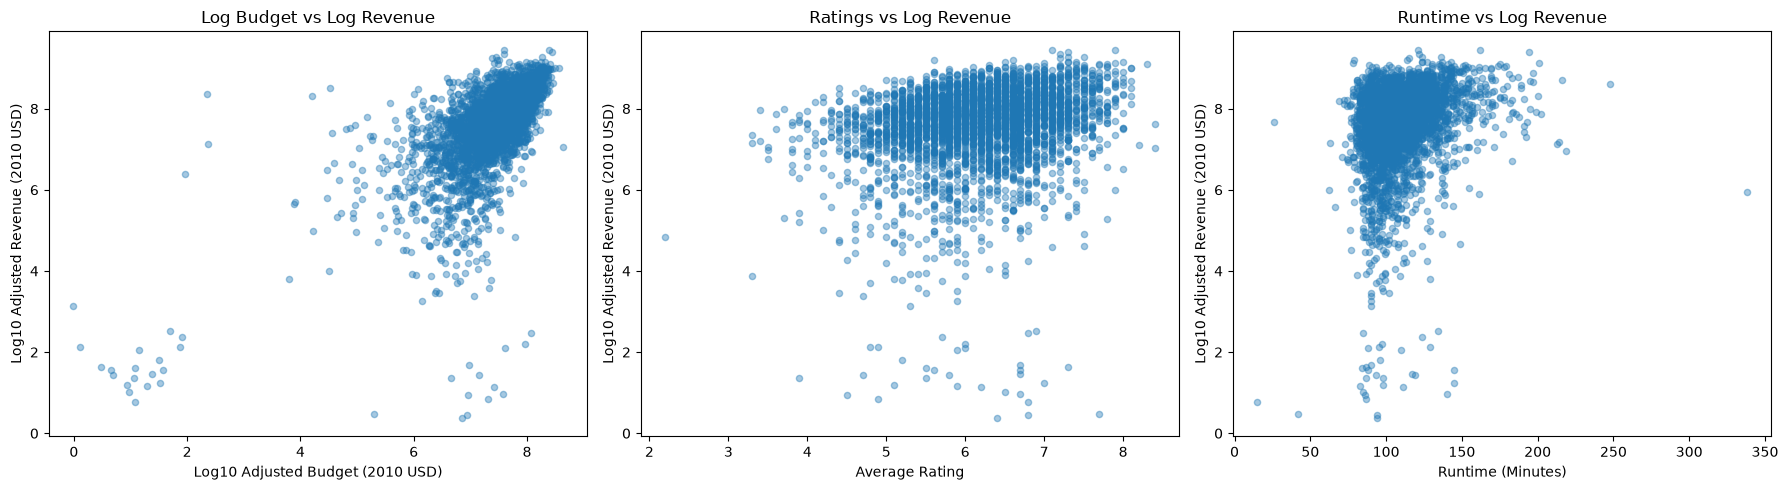

In [65]:
# Apply NumPy to arrays of positive financial values
df_financial['log_budget'] = np.log10(df_financial['budget_adj'].to_numpy())
df_financial['log_revenue'] = np.log10(df_financial['revenue_adj'].to_numpy())

# Reusable function for scatter plots
def plot_relationship(x_column, title, xlabel, ax):
    df_financial.plot(
        kind='scatter',
        x=x_column,
        y='log_revenue',
        ax=ax,
        alpha=0.4
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Log10 Adjusted Revenue (2010 USD)')


# Create three scatter plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_relationship(
    'log_budget',
    'Log Budget vs Log Revenue',
    'Log10 Adjusted Budget (2010 USD)',
    axes[0]
)

plot_relationship(
    'vote_average',
    'Ratings vs Log Revenue',
    'Average Rating',
    axes[1]
)

plot_relationship(
    'runtime',
    'Runtime vs Log Revenue',
    'Runtime (Minutes)',
    axes[2]
)

plt.tight_layout();

### Bivariate Analysis (2D): Movie Revenue Relationships

The scatter plots explore the relationships between log10 adjusted movie revenue and three variables: log10 adjusted budget, average rating, and runtime. The financial axes show base-10 logarithms of amounts in 2010 US dollars; ratings and runtime remain on their original scales.

**1. Budget vs Revenue**

The plot suggests a positive association between budget and revenue. Higher-budget movies generally tend to generate higher revenues, although there is substantial variation among movies with similar budgets.

**2. Ratings vs Revenue**

The plot suggests a weaker positive association between ratings and revenue. Movies with similar ratings still have widely varying revenues, and a high rating does not guarantee high revenue.

**3. Runtime vs Revenue**

The plot suggests a weaker positive association between runtime and revenue. Most movies are concentrated within a relatively narrow runtime range, while their revenues vary considerably.

**Overall Observation**

Budget appears to have the clearest positive association with revenue among the three variables. Correlation analysis will be used to examine these relationships more systematically. These visual observations do not establish causation.

In [66]:
# Calculate Spearman correlations with adjusted revenue
variables = [
    'revenue_adj',
    'budget_adj',
    'vote_average',
    'runtime'
]

correlations = df_financial[variables].corr(method='spearman')

correlations['revenue_adj'].round(3)

revenue_adj     1.000
budget_adj      0.656
vote_average    0.240
runtime         0.284
Name: revenue_adj, dtype: float64

### Spearman Correlation Findings

Spearman correlation is used to examine monotonic associations without requiring the relationships to be linear. This complements the scatter plots, particularly given the strongly right-skewed financial variables.

Adjusted budget has the strongest positive association with adjusted revenue (Spearman correlation = 0.656). Movie ratings (0.240) and runtime (0.284) show weaker positive associations.

These findings support the scatter plot observations. However, correlation does not imply causation, and the results apply only to the 3,854 movies with positive adjusted budgets and revenues. No statistical significance tests were performed.

### Research Question 2: How Does Adjusted Movie Revenue Vary by Genre and Five-Year Release Period?

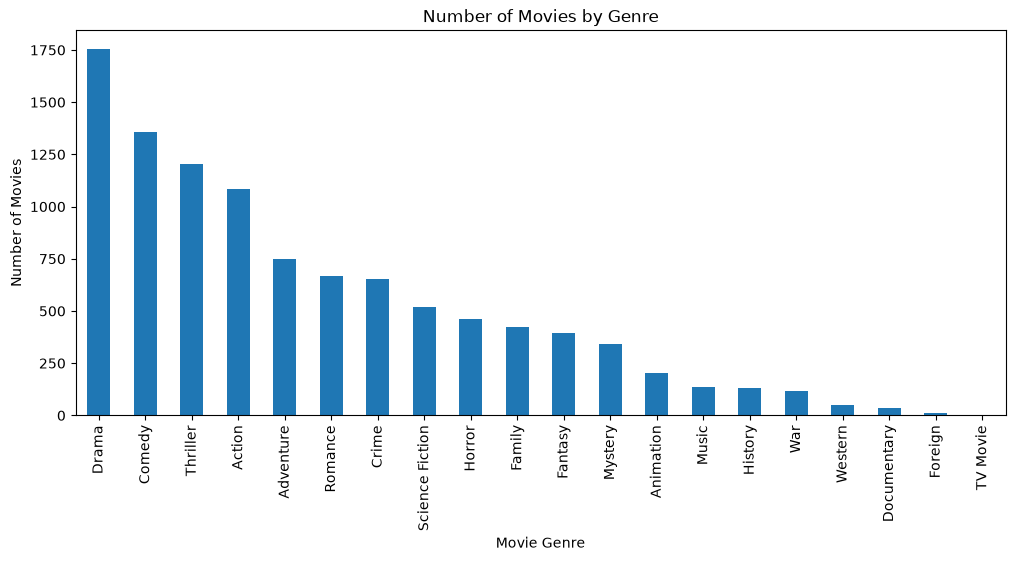

In [67]:
# Count movies in each genre
genre_counts = (
    df_financial['genres']
    .str.split('|')
    .explode()
    .value_counts()
)

# Visualize genre frequencies
ax = genre_counts.plot(
    kind='bar',
    figsize=(12, 5)
)

ax.set_title('Number of Movies by Genre')
ax.set_xlabel('Movie Genre')
ax.set_ylabel('Number of Movies');

### Movie Genre Distribution

The bar chart shows that Drama is the most common genre in the financial dataset, followed by Comedy, Thriller, and Action.

Some genres, including Documentary, Foreign, and TV Movie, appear much less frequently.

Since movies can belong to multiple genres, each movie is counted once for every genre associated with it. Therefore, the total genre counts may exceed the number of unique movies.

This analysis describes genre frequency, not revenue performance.

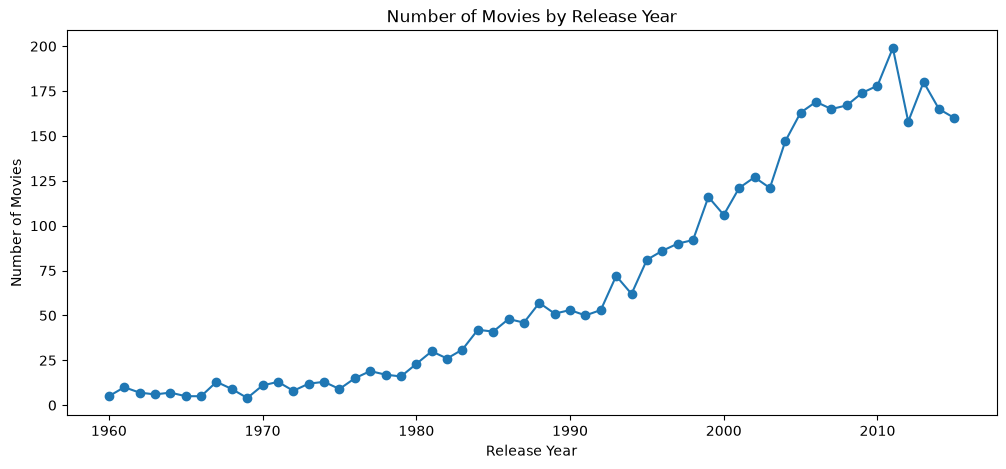

In [68]:
# Count movies released each year
year_counts = df_financial['release_year'].value_counts().sort_index()

# Visualize movie counts over time
ax = year_counts.plot(
    kind='line',
    figsize=(12, 5),
    marker='o'
)

ax.set_title('Number of Movies by Release Year')
ax.set_xlabel('Release Year')
ax.set_ylabel('Number of Movies');

### Movie Distribution by Release Year

The line plot shows an overall increase in the number of movies represented in the financial dataset from 1960 to 2015.

The number of movies increased particularly during the 2000s, reaching a peak around 2011, with approximately 200 movies.

Although the number fluctuates in later years, it remains considerably higher than in earlier decades.

However, this trend reflects only movies with positive adjusted budgets and revenues in the selected dataset. It does not necessarily represent the total number of movies produced worldwide.

In [69]:
# Separate movies into their individual genres
genre_data = df_financial.assign(
    genres=df_financial['genres'].str.split('|')
).explode('genres')

# Calculate revenue statistics for each genre
genre_revenue = genre_data.groupby('genres')['revenue_adj'].agg(
    ['count', 'mean', 'median']
)

# Display the results sorted by median revenue
genre_revenue.sort_values('median', ascending=False)

,count,mean,median
genres,,,
Animation,201,2.909574e+08,2.057296e+08
Adventure,749,2.714075e+08,1.445834e+08
Family,425,2.437910e+08,1.306618e+08
Fantasy,396,2.499928e+08,1.193492e+08
Action,1085,1.953879e+08,9.488289e+07
War,119,1.558981e+08,8.990674e+07
Science Fiction,519,2.021531e+08,8.361457e+07
History,129,1.216617e+08,7.485721e+07
Western,52,1.356748e+08,7.286339e+07


### Revenue Analysis by Genre

To compare movie revenues across genres, both mean and median revenues were calculated for each genre.

Since the revenue distribution is strongly right-skewed, the median was selected as the main measure for comparison because it is less affected by extremely high-revenue movies.

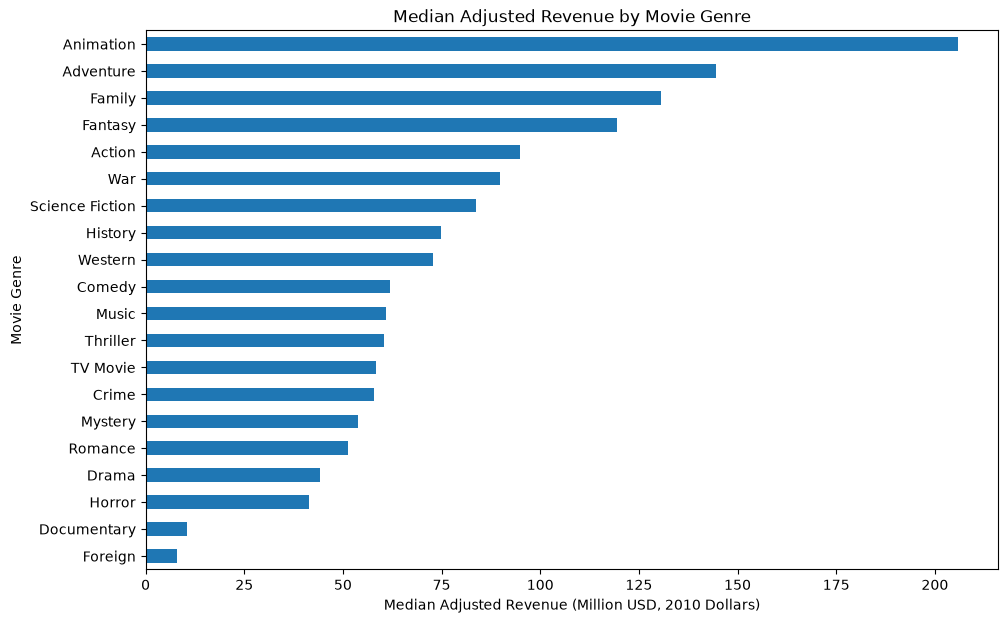

In [70]:
# Calculate median revenue in millions for each genre
median_revenue = (
    genre_revenue['median']
    .sort_values(ascending=True)
    / 1_000_000
)

# Plot median revenue by genre
ax = median_revenue.plot(
    kind='barh',
    figsize=(11, 7)
)

ax.set_title('Median Adjusted Revenue by Movie Genre')
ax.set_xlabel('Median Adjusted Revenue (Million USD, 2010 Dollars)')
ax.set_ylabel('Movie Genre');

### Movie Genre and Adjusted Revenue

The analysis shows that Animation has the highest median adjusted revenue at approximately $205.73 million, followed by Adventure ($144.58 million) and Family ($130.66 million).

Although Drama is the most common genre in the dataset, its median revenue is approximately $44.27 million, which is considerably lower than that of several other genres.

These findings suggest that genre is associated with differences in movie revenue. However, some genres have small sample sizes, and movies may belong to multiple genres. Therefore, the results should be interpreted cautiously.

In [71]:
# Check movie counts and median revenue in the 1960s
df_financial.groupby('release_year')['revenue_adj'].agg(
    ['count', 'median']
).loc[1960:1969].style.format({
    'median': '{:,.2f}'
})

,count,median
release_year,,
1960,5,"184,324,186.43"
1961,10,"71,124,896.78"
1962,7,"94,645,823.68"
1963,6,"88,568,327.73"
1964,7,"84,363,208.92"
1965,5,"773,178,594.14"
1966,5,"87,334,191.00"
1967,13,"296,115,397.41"
1968,9,"131,648,235.91"


### Examining the 1960s Data

This analysis checks the number of movies and median adjusted revenue for each year during the 1960s.

The purpose is to investigate whether unusually high yearly median revenues are based on small sample sizes, which may affect the reliability of comparisons between years.

In [72]:
# Group movies into 5-year periods
df_financial['period_5y'] = (
    df_financial['release_year'] // 5
) * 5

# Calculate movie counts and median revenue
period_stats = df_financial.groupby('period_5y')['revenue_adj'].agg(
    ['count', 'median']
)

# Convert median revenue to millions
period_stats['median_millions'] = (
    period_stats['median'] / 1_000_000
)

period_stats[['count', 'median_millions']].round(2)

,count,median_millions
period_5y,,
1960,35,84.36
1965,36,209.35
1970,57,157.43
1975,76,119.42
1980,152,71.74
1985,243,56.00
1990,290,55.58
1995,465,60.22
2000,622,73.52


### Grouping Movies by Five-Year Release Period

Movies were grouped into five-year release periods to reduce yearly fluctuations and provide a clearer view of revenue patterns over time.

For each period, the number of movies and median adjusted revenue were calculated. The median was chosen because it is less sensitive to extremely high-revenue movies, while movie counts help assess differences in sample sizes between periods.

Each period is labeled by its starting year. For example, 1965 represents 1965-1969. The final group, labeled 2015, contains only movies from 2015 because that is the last year covered by the dataset.

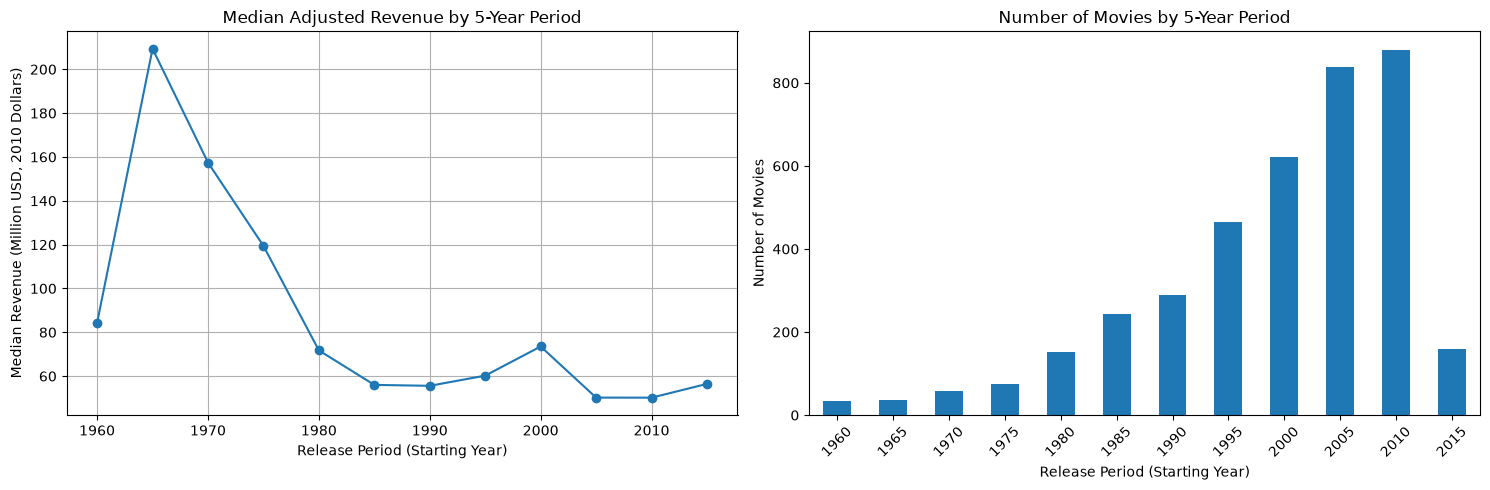

In [73]:
# Compare median revenue and movie counts across 5-year periods
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

period_stats['median_millions'].plot(
    kind='line',
    ax=axes[0],
    marker='o'
)

axes[0].set_title('Median Adjusted Revenue by 5-Year Period')
axes[0].set_xlabel('Release Period (Starting Year)')
axes[0].set_ylabel('Median Revenue (Million USD, 2010 Dollars)')
axes[0].grid(True)

period_stats['count'].plot(
    kind='bar',
    ax=axes[1]
)

axes[1].set_title('Number of Movies by 5-Year Period')
axes[1].set_xlabel('Release Period (Starting Year)')
axes[1].set_ylabel('Number of Movies')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout();

### Adjusted Revenue Trends by 5-Year Period

**Median Adjusted Revenue**

The line plot shows that median adjusted revenue varies across five-year periods. The highest median occurs during 1965–1969, at approximately $209 million.

Median revenue generally declines in subsequent periods. From the mid-1980s onward, it fluctuates within a relatively narrower range, with no consistent upward trend.

**Number of Movies**

The bar chart shows an overall increase in the number of movies represented in the dataset across successive five-year periods, with considerably more movies in recent periods than in earlier ones.

**Interpretation and Limitations**

Earlier periods contain relatively small samples. For example, the 1965–1969 group contains only 36 movies, so its high median revenue should be interpreted cautiously.

The final period contains only movies released in 2015 and is not directly comparable in movie count to complete five-year periods.

Additionally, the analysis includes only movies with positive adjusted budgets and revenues, limiting the generalizability of these findings.

<a id='conclusions'></a>
## Conclusions

This investigation explored how adjusted movie revenue is associated with budget, audience ratings, runtime, genre, and release period. The analysis focused on 3,854 movies with positive adjusted budgets and revenues. All financial figures discussed below are expressed in 2010 US dollars.

Adjusted budget had the strongest positive association with adjusted revenue, with a Spearman correlation of **0.656**. Audience ratings (**0.240**) and runtime (**0.284**) showed weaker positive associations. These relationships describe patterns in the selected sample and do not establish causation or statistical significance.

Revenue also varied across genres. **Animation** had the highest median adjusted revenue at approximately **$205.73 million**, followed by **Adventure** ($144.58 million) and **Family** ($130.66 million). Drama was the most common genre, but its median revenue was lower at approximately $44.27 million.

Across five-year release periods, **1965-1969** had the highest median adjusted revenue, at approximately **$209.35 million**. However, this period contained only 36 movies. Later periods showed fluctuations without a consistent upward trend, despite containing more movies in the selected dataset.

### Limitations and Further Investigation

- Excluding movies with zero budgets or revenues reduced the sample considerably and may introduce selection bias. This also excludes movies with positive reported revenue but a zero reported budget. The findings cannot be generalized to all movies.
- Movies can belong to multiple genres, so genre groups overlap. Some genres contain very few movies, making their comparisons less reliable.
- Earlier release periods contain smaller samples, while the final period includes only 2015. Movie counts in that final group are not directly comparable to those in complete five-year periods.
- Very small positive budget and revenue values were retained because there was insufficient evidence to classify them as errors; uncertainty about their quality remains.
- The analysis examined each relationship separately and did not control for other factors that may influence revenue. No statistical significance tests were performed.

Further investigation could examine whether genre differences remain after accounting for budget, compare revenue patterns using all movies with positive reported revenue, and explore additional factors such as marketing expenditure and distribution reach if those data become available.

## Exporting the Report

The following cell converts the notebook to an HTML report when run manually.

In [74]:
# Running this cell will execute a bash command to convert this notebook to an .html file
!python -m nbconvert --to html Investigate_a_Dataset.ipynb

[NbConvertApp] Converting notebook Investigate_a_Dataset.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 945205 bytes to Investigate_a_Dataset.html
